# 2 · Without the experiment: selection bias

Now we do what LaLonde did. Keep the 185 people who got the program, **throw away the randomized controls**, and compare against 15,992 people from the Current Population Survey (CPS) instead.

This is exactly the HR situation: you have the people who went through the program, and everyone else in the HRIS.

**What you'll learn**
- What a naive comparison gets wrong, and by how much
- The decomposition: naive difference = true effect + selection bias
- How to measure balance with standardized mean differences (and why not p-values)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import loadData

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
experiment, cps = loadData()

treatedGroup = experiment[experiment.treat == 1]
experimentalControls = experiment[experiment.treat == 0]
observational = pd.concat([treatedGroup, cps], ignore_index=True)  # cps rows already have treat = 0

benchmark = treatedGroup.re78.mean() - experimentalControls.re78.mean()
print(observational.treat.value_counts().rename({1: "treated", 0: "cps controls"}))

treat
cps controls    15992
treated           185
Name: count, dtype: int64


> **Predict first.** The benchmark is about +$1,794. Will the naive comparison with CPS controls come out higher, lower, or about the same? Why?

In [2]:
naive = treatedGroup.re78.mean() - cps.re78.mean()
print(f"treated mean re78:  ${treatedGroup.re78.mean():,.0f}")
print(f"cps mean re78:      ${cps.re78.mean():,.0f}")
print(f"naive difference:   ${naive:,.0f}")
print(f"benchmark:          ${benchmark:,.0f}")

treated mean re78:  $6,349
cps mean re78:      $14,847
naive difference:   $-8,498
benchmark:          $1,794


The naive comparison says the program **cut** earnings by about $8,500. The true effect is a **gain** of about $1,800. Wrong sign, wrong size, and the standard error would look tiny with 16,000 controls. A confident, precise, wrong answer.

## 1. Where the error comes from

Add and subtract the same term, $E[Y(0) \mid T=1]$:

$$
\underbrace{E[Y \mid T=1] - E[Y \mid T=0]}_{\text{naive difference}}
= \underbrace{E[Y(1) - Y(0) \mid T=1]}_{\text{ATT}}
\; + \; \underbrace{E[Y(0) \mid T=1] - E[Y(0) \mid T=0]}_{\text{selection bias}}
$$

**Selection bias** is the difference between what the treated group would have earned without the program and what the comparison group actually earned. In notebook 1, randomization made it zero. Here it isn't.

Normally you can't compute it, because $E[Y(0) \mid T=1]$ is unobservable. **Here we can**, because the experimental controls tell us exactly that number.

In [3]:
att = treatedGroup.re78.mean() - experimentalControls.re78.mean()          # what we want
selectionBias = experimentalControls.re78.mean() - cps.re78.mean()         # the contamination

print(f"ATT (benchmark):  ${att:,.0f}")
print(f"selection bias:   ${selectionBias:,.0f}")
print(f"sum:              ${att + selectionBias:,.0f}")
print(f"naive difference: ${naive:,.0f}   <- identical")

ATT (benchmark):  $1,794
selection bias:   $-10,292
sum:              $-8,498
naive difference: $-8,498   <- identical


The selection bias is about **−$10,300**. The people in the program would have earned far less than the average CPS respondent *even without the program*. The naive comparison mixes up "who signed up" with "what the program did."

## 2. Measuring the difference before the program: balance

If the groups differ in who they are, we should see it in variables measured **before** the program. The standard tool is the **standardized mean difference (SMD)**:

$$SMD = \frac{\bar x_{T} - \bar x_{C}}{\sqrt{(s_T^2 + s_C^2)/2}}$$

It's the gap in means, measured in pooled standard deviations, so you can compare age (years) and earnings (dollars) on one scale.

**Rule of thumb:** $|SMD| < 0.1$ is good balance. Above 0.25 is a serious problem.

**Why not t-tests?** A p-value depends on sample size. With 16,000 controls, a trivial difference is "significant"; with 40 people, a huge one isn't. Balance is a property of *this sample*, not a hypothesis about a population, so we describe it rather than test it.

In [4]:
def smd(x, t):
    # standardized mean difference: gap in means divided by the pooled standard deviation
    x, t = np.asarray(x, float), np.asarray(t)
    pooledSd = np.sqrt((x[t == 1].var(ddof=1) + x[t == 0].var(ddof=1)) / 2)
    return (x[t == 1].mean() - x[t == 0].mean()) / pooledSd

covariates = ["age", "educ", "black", "hisp", "marr", "nodegree", "re74", "re75"]

balance = pd.DataFrame({
    "treated_mean": treatedGroup[covariates].mean(),
    "exp_control_mean": experimentalControls[covariates].mean(),
    "cps_mean": cps[covariates].mean(),
    "smd_vs_exp_controls": [smd(experiment[c], experiment.treat) for c in covariates],
    "smd_vs_cps": [smd(observational[c], observational.treat) for c in covariates],
})
balance.round(2)

,treated_mean,exp_control_mean,cps_mean,smd_vs_exp_controls,smd_vs_cps
age,25.82,25.05,33.23,0.11,-0.80
educ,10.35,10.09,12.03,0.14,-0.68
black,0.84,0.83,0.07,0.04,2.43
hisp,0.06,0.11,0.07,-0.17,-0.05
marr,0.19,0.15,0.71,0.09,-1.23
nodegree,0.71,0.83,0.30,-0.30,0.90
re74,"2,095.57","2,107.03","14,016.80",-0.00,-1.57
re75,"1,532.06","1,266.91","13,650.80",0.08,-1.75


Read across a row. Against the experimental controls, most SMDs are small (`nodegree` and `hisp` show the chance gaps you saw in notebook 1). Against CPS, most are enormous:

- **Earnings before the program** (`re74`, `re75`): treated people earned about $1,500 to $2,100; CPS people earned about $13,000 to $14,000. SMDs beyond −1.5.
- **Who they are:** the program served mostly young, Black, unmarried men without a high school degree. CPS is a cross-section of working adults.

That's not a flaw in the program. It's who the program was *designed* for. But it means CPS people are a terrible stand-in for $Y(0)$.

(This SMD function is saved in `utils.py` so the next notebooks can reuse it.)

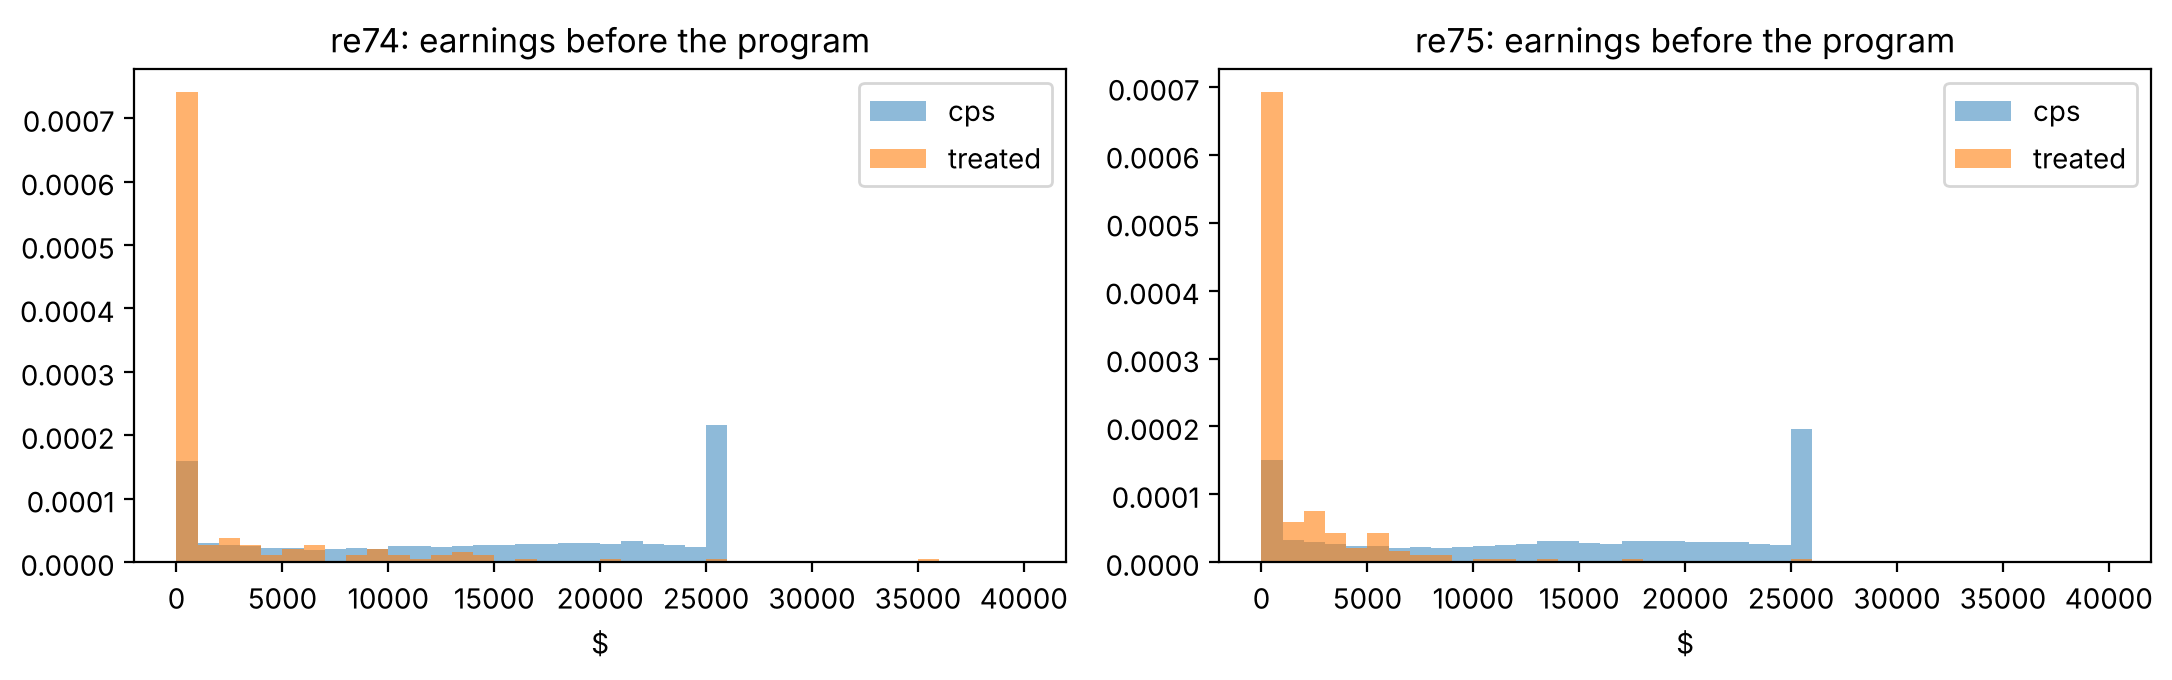

,treated,cps
share with $0 in 1974,0.71,0.12
share with $0 in 1975,0.60,0.11


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
bins = np.linspace(0, 40000, 41)
for ax, col in zip(axes, ["re74", "re75"]):
    ax.hist(cps[col], bins=bins, density=True, alpha=0.5, label="cps")
    ax.hist(treatedGroup[col], bins=bins, density=True, alpha=0.6, label="treated")
    ax.set_title(f"{col}: earnings before the program")
    ax.set_xlabel("$")
    ax.legend()
plt.tight_layout()
plt.show()

zeroEarnings = pd.DataFrame({
    "treated": [(treatedGroup.re74 == 0).mean(), (treatedGroup.re75 == 0).mean()],
    "cps": [(cps.re74 == 0).mean(), (cps.re75 == 0).mean()],
}, index=["share with $0 in 1974", "share with $0 in 1975"])
zeroEarnings.round(2)

Most program participants earned **nothing** in 1974 and 1975; most CPS people earned a full salary. No regression coefficient can make those two groups comparable by itself. Notebook 3 shows what can.

---

### Check your understanding

1. Write the decomposition from memory: naive difference = ? + ?
2. In HR: "Employees who attended optional leadership training were promoted 2x as often." Name two reasons that could be selection bias rather than a training effect.
3. Someone shows you a balance table with p-values, all above 0.05, from a sample of 60 people. Are the groups balanced?

<details><summary>Answers</summary>

1. Naive difference = ATT + selection bias, where selection bias = $E[Y(0)\mid T=1] - E[Y(0)\mid T=0]$.
2. Ambitious people sign up for optional training *and* get promoted more; managers nominate their strongest people. Higher performers would have been promoted anyway.
3. Not necessarily. With 60 people, a t-test can't detect even big gaps. Look at the SMDs instead.
</details>

### Interview line
> "A naive comparison of program participants with everyone else answers 'who signs up,' not 'what the program does.' Before estimating anything, I check balance on pre-program variables with standardized mean differences, because that tells me how hard the comparison problem is."